# AI assisted lexical census of contestability wording in ATRS records
**Team Avengers · Gr10 · Fatih Ridvan Kizik and Dheeraj Erpa**

## Revised research design approved by the user on 9 November 2026
- The study is a deterministic documentary lexical census of all 153 records in the frozen 26 October snapshot. Every published record is eligible for this wording census, including internal tools and general information systems. This is an intentional scope change from the earlier individual-decision eligibility design.
- AI assistance was used to write and review code and to contextualize selected guidance links. No independent human annotation, adjudication, human agreement, semantic accuracy, or population representativeness is claimed.
- A lexical positive means the published sentence matches the stated rules. It does not mean an operational safeguard exists. Non-detection is not an absence finding. Seven cue types are not a validated quality index.
- Decision-role and rationale categories are rule-assigned wording categories, not validated descriptions of actual roles or judgments of rationale consistency. Legal consistency is outside this revised study.
- Two cue analyses are provided: all matches, and removal of matches in sentences containing predefined negation cues. This is a diagnostic sensitivity analysis; negation cues do not prove that a statement is negated.
- Archived links collected on 9 November are supplementary contextual material. They do not alter the frozen record measures. Inaccessible pages remain explicit. The direct-link candidate inventory is not exhaustive of all potentially relevant guidance.
- The original proposal and original release remain preserved. This revision has not been approved by the instructor or accepted by the target journal Government Information Quarterly.

## Method
- M1 Verify the JSON checksum, unique IDs, source URLs and 157 archived-response hashes. Use all records and report stage/template composition.
- M2 Apply the disclosed sentence rules to the archived sections; retain exact excerpts, URLs and negation flags. Publish patterns as a rule catalogue.
- M3 Assign appeals-wording and decision-role cue categories; retain mixed/unclear categories. Generate the seven binary cue indicators and joint oversight/review states.
- M4 Answer RQ1 to RQ5 with descriptive proportions, cross-tabulations, seeded jitter, rank correlations, deterministic contrasting examples and predefined stage/template subsets. No population p-values or causal estimates.
- M5 Repeat cue counts with negation-cue sentences removed. Keep later linked-guidance review separate from record-level measurements.
- M6 Export 10 PDF/PNG figures and 10 main CSV tables, supplementary diagnostics, captions, metadata, source evidence, file checksums and one ZIP. Display all main results inline.


## Research questions

RQ1. How frequently do seven predefined contestation-related wording patterns occur in the frozen 153-record ATRS corpus, and which combinations co-occur?

RQ2. Which predefined appeals-wording categories occur across deployment stages and decision-role cue categories, and what source passages illustrate them?

RQ3. How do contestation-related cue profiles vary across automatically assigned decision-role cue categories and stage or template subsets?

RQ4. How is archived record length associated with the number of detected contestation-related cue types, and which similarly long records contrast?

RQ5. How do routine-oversight cues and affected-person review cues co-occur in the published records?

### M1 Configure the frozen wording census
Use a new dated output directory; no model training or human-code inputs.

In [1]:
# M1 — Configuration and reproducibility
# Set the analysis mode, portable input paths and a fresh output folder. All RQs use the same frozen input.
import os, re, json, hashlib, zipfile, math, platform, textwrap, sys
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, FileLink

MODE = 'AI_ASSISTED_LEXICAL_CENSUS'
DATA_FILE = None      # Optional explicit path to atrs_records.json.
SEED = 2601026
EXPECTED_SHA256 = '3c658cfbdd8bb6f45e2562c106e88fdec0e27d98af364aca267343b7a5102db8'
SNAPSHOT_DATE = '2026-10-26'
assert MODE == 'AI_ASSISTED_LEXICAL_CENSUS'
BASE = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RESULTS = BASE / f'atrs_results_{MODE.lower()}_{RUN_ID}'
for folder in ['figures','tables','plot_data','audit','supplementary_guidance']:
    (RESULTS/folder).mkdir(parents=True, exist_ok=False)
STATUS = 'AUTOMATED LEXICAL CENSUS | 153 published records'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':12,
                     'axes.labelsize':10,'pdf.fonttype':42,'ps.fonttype':42,
                     'axes.spines.top':False,'axes.spines.right':False,'savefig.dpi':300})
COLORS=['#0072B2','#E69F00','#009E73','#CC79A7','#56B4E9','#D55E00','#737373','#332288']
ARTIFACTS=[]
print('Mode:',MODE,'| Snapshot:',SNAPSHOT_DATE,'| Output:',RESULTS)

Mode: AI_ASSISTED_LEXICAL_CENSUS | Snapshot: 2026-10-26 | Output: /Users/fatih/Desktop/MS Data Science/AI, Power & Responsibility – Governing Intell/outputs/research_completion_2026-11-09/census/atrs_results_ai_assisted_lexical_census_20261109T183352831540Z


### M1 Verify sources and report corpus composition
All 153 published records are the defined census population; no individual-decision eligibility claim.

In [2]:
# M1 — Load and verify the frozen corpus
# Verify the dataset and every archived-response checksum before analysing any research question.
def sha256_file(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
if DATA_FILE:
    source=Path(DATA_FILE)
else:
    candidates=[]
    for base in [Path('/kaggle/input'),Path.cwd()/'input_data',Path.cwd()/'data']:
        if base.exists(): candidates.extend(base.rglob('atrs_records.json'))
    candidates=sorted(set(p.resolve() for p in candidates))
    matches=[p for p in candidates if sha256_file(p)==EXPECTED_SHA256]
    if not matches:
        raise FileNotFoundError('Attach/extract ATRS_Kaggle_Input.zip. Expected data/atrs_records.json with the frozen checksum; do not substitute a live download.')
    source=matches[0]
assert sha256_file(source)==EXPECTED_SHA256,'Frozen dataset checksum differs.'
INPUT_ROOT=source.parent.parent
records=json.loads(source.read_text(encoding='utf-8'))
df=pd.DataFrame(records)
required=['record_id','title','source_url','phase','atrs_version','word_count_body','text_path',
          'process_text','appeals_text','human_review_text','owner_text']
assert set(required)<=set(df.columns)
assert len(df)==153 and df.record_id.is_unique and df.source_url.is_unique
assert df.source_url.str.startswith('https://www.gov.uk/algorithmic-transparency-records/').all()
manifest=json.loads((INPUT_ROOT/'metadata/download_manifest.json').read_text())
hash_checks=[]
for item in manifest:
    p=INPUT_ROOT/item['path']
    assert p.exists(),f'Missing archived file: {p}'
    ok=sha256_file(p)==item['sha256']
    hash_checks.append({'path':item['path'],'sha256_ok':ok})
    assert ok, f'Archived response changed: {p}'
pd.DataFrame(hash_checks).to_csv(RESULTS/'audit/input_hash_checks.csv',index=False)
df['full_text']=[(INPUT_ROOT/p).read_text(encoding='utf-8') for p in df.text_path]
df['version']=df.atrs_version.fillna('').str.lower().str.replace('v','',regex=False).str.split('.').str[0].map(lambda s:'v'+s)
df['stage']=np.select([df.phase.eq('Production'),df.phase.eq('Retired'),df.phase.eq('Pre-deployment')],
                      ['Production','Retired','Planned'],default='Pilot / beta')
assert (pd.to_numeric(df.word_count_body,errors='coerce')>0).all()
df['words']=df.word_count_body.astype(int)
df['log_words']=np.log10(df.words)
df['title']=df.title.str.strip()
print(f'Verified {len(df)} records and {len(hash_checks)} archived files. No live sources were substituted.')
display(df.groupby(['version','stage'],dropna=False).size().rename('records').reset_index())

Verified 153 records and 157 archived files. No live sources were substituted.


,version,stage,records
0,v1,Planned,1
1,v1,Production,3
2,v1,Retired,3
3,v2,Pilot / beta,2
4,v2,Production,2
5,v3,Pilot / beta,19
6,v3,Planned,4
7,v3,Production,64
8,v3,Retired,1
9,v4,Pilot / beta,25


### M2 Extract exact source linked lexical evidence
RQ1 to RQ5. Rules identify wording only; timing patterns include filing deadlines and cannot be described as response times.

In [3]:
# M3 and M4 — Transparent evidence extraction
# Generate inspectable lexical candidates for RQ1–RQ5. Non-detection never means a safeguard is absent; rationale consistency stays unassessed.
FEATURES=['channel','requirements','reviewer','scope','timing','remedy','escalation']
LABELS={'channel':'Channel wording','requirements':'Submission wording','reviewer':'Reviewer wording',
        'scope':'Review scope wording','timing':'Timing wording','remedy':'Remedy wording','escalation':'Escalation wording'}
CONTEST=re.compile(r'\b(appeal\w*|complaint\w*|contest\w*|challeng\w*|disput\w*|reconsider\w*|redress)\b',re.I)
PATTERNS={
 'channel':r'\b(contact|email|e-mail|post|telephone|phone|submit|write|respond|reply|form|online|website)\b|[\w.+-]+@[\w.-]+\.[a-z]{2,}',
 'requirements':r'\b(provide|submit|include|enclose|supply)\b.{0,100}\b(evidence|reason|details|information|document)',
 'reviewer':r'\b(review|appeal|complaint)\w*\b.{0,90}\b(team|officer|manager|staff|human|person|practitioner|ombudsman|tribunal)|\b(team|officer|manager|staff|human|practitioner)\b.{0,90}\b(review|appeal|complaint)',
 'scope':r'\b(review|reconsider|challenge|appeal|dispute)\w*\b.{0,100}\b(decision|outcome|assessment|award|evidence|eligibility)',
 'timing':r'\b(\d+\+?|one|two|three|four|five|ten|twenty|thirty|forty)\s*(working\s+|business\s+)?(day|week|month)s?\b|\b(deadline|timeframe|time frame)\b',
 'remedy':r'\b(overturn|revers|correct|amend|rectif|compensat|refund|remed|reassess|reconsider)\w*|\b(change|revise)\w*\b.{0,45}\b(decision|outcome|record|award)',
 'escalation':r'\b(escalat|ombudsman|tribunal|judicial review|independent review|further appeal|second.stage)\w*'}
NEGATION=re.compile(r'\b(no|not|never|cannot|can\x27t|without|unavailable|unlikely)\b',re.I)
sections=[json.loads(line) for line in (INPUT_ROOT/'data/atrs_sections.jsonl').read_text().splitlines() if line.strip()]
section_map={rid:[] for rid in df.record_id}
for s in sections:section_map[s['record_id']].append(s)
def sentences(text):
    return [re.sub(r'\s+',' ',x).strip() for x in re.split(r'(?<=[.!?])\s+|\n+',str(text or '')) if x.strip()]
evidence=[]; auto=[]
for _,row in df.iterrows():
    rid=row.record_id; hits={f:[] for f in FEATURES}; contest_sent=[]
    for sec in section_map[rid]:
        for sent in sentences(sec.get('text','')):
            # Only sentences with an explicit contestation cue supply procedural candidates.
            if CONTEST.search(sent):
                contest_sent.append((sent,sec['source_section_url']))
                for f,pat in PATTERNS.items():
                    if re.search(pat,sent,re.I):
                        hits[f].append(sent)
                        evidence.append({'record_id':rid,'title':row.title,'variable':f,'candidate_value':'detected',
                                         'evidence':sent,'source_url':sec['source_section_url'],
                                         'negation_flag':bool(NEGATION.search(sent)), 'status':'unvalidated lexical candidate'})
    a=str(row.appeals_text or '').strip(); lower=a.lower()
    # Ordered lexical categories are exclusive for display; they are not legal conclusions.
    if not a: rationale='Missing extracted appeals text'
    elif re.fullmatch(r'(n\s*/?\s*a|not applicable|none)[.\s]*',lower): rationale='Bare NA / none wording'
    elif re.search(r'(normal|standard|existing|usual|ordinary).{0,45}(appeal|complaint)|(appeal|complaint).{0,45}(normal|standard|existing|usual|ordinary)',lower): rationale='Ordinary process reference'
    elif re.search(r'(no|not|does not).{0,65}(automat\w*.{0,20}decision)|decision.{0,50}(human|person)|human.{0,45}(decision|decide)',lower): rationale='Human or nonautomated decision wording'
    elif re.search(r'not applicable|no.{0,15}(appeal|formal)|not.{0,30}(required|necessary|relevant)',lower): rationale='Nonapplicability / no route wording'
    elif CONTEST.search(a): rationale='Other contestation wording'
    else:rationale='Other / unclear wording'
    # Split each source field separately so evidence never joins unrelated sections.
    process_sentences=[s for k in ['description_text','process_text','human_review_text']
                       for s in sentences(row.get(k,'') or '')]
    role_patterns={
      'Determine':r'\b(automatically|automated|automatic)\b.{0,75}\b(decid\w*|decision|assess\w*|eligib\w*|approv\w*|reject\w*)',
      'Recommend':r'\b(recommend\w*|decision support|support.{0,20}decision)\b',
      'Prioritize':r'\b(prioriti[sz]\w*|triag\w*|rank\w*|risk.{0,15}(score|rating)|refer\w*.{0,35}(investigat|review))'}
    roles=[]
    for role,pat in role_patterns.items():
        matches=[s for s in process_sentences if re.search(pat,s,re.I)]
        if matches:
            roles.append(role)
            evidence.append({'record_id':rid,'title':row.title,'variable':'decision_role','candidate_value':role,
              'evidence':matches[0],'source_url':row.source_url,'negation_flag':bool(NEGATION.search(matches[0])), 'status':'unvalidated lexical candidate'})
    role=roles[0] if len(roles)==1 else ('Mixed cues' if roles else 'Unclear')
    hr=sentences(row.human_review_text)
    routine=[s for s in hr if re.search(r'\b(human|staff|officer|practitioner|caseworker|employee|team)\b',s,re.I)
             and re.search(r'\b(review|check|validat|assess|decid|decision|overrid|supervis|monitor)\w*',s,re.I)]
    citizen=[(s,u) for s,u in contest_sent if re.search(r'\b(citizen|person|people|individual|applicant|customer|claimant|user|patient|public|they|you)\w*\b',s,re.I)
             and re.search(r'\b(can|may|request|submit|contact|right|able|wish|appeal)\w*\b',s,re.I)]
    for var,ss,url in [('routine_oversight',routine,row.get('human_review_source_url') or row.source_url),
                        ('citizen_review',[x[0] for x in citizen],citizen[0][1] if citizen else row.source_url)]:
        if ss:evidence.append({'record_id':rid,'title':row.title,'variable':var,'candidate_value':'detected',
             'evidence':ss[0],'source_url':url,'negation_flag':bool(NEGATION.search(ss[0])),'status':'unvalidated lexical candidate'})
    auto.append({'record_id':rid,**{f:('detected' if hits[f] else 'not_detected') for f in FEATURES},
       'decision_role':role,'rationale':rationale,'consistency':'Not assessed',
       'routine_oversight':'detected' if routine else 'not_detected',
       'citizen_review':'detected' if citizen else 'not_detected'})
auto=pd.DataFrame(auto)
evidence=pd.DataFrame(evidence).drop_duplicates(['record_id','variable','candidate_value','evidence','source_url'])
auto.to_csv(RESULTS/'audit/machine_candidates_NOT_HUMAN_CODES.csv',index=False)
evidence.to_csv(RESULTS/'audit/machine_evidence.csv',index=False)
print(f'{len(evidence)} exact source passages flagged; {int(evidence.negation_flag.sum())} include negation cues requiring special review.')
print('All 153 published records define the wording census; semantic eligibility and legal consistency are outside this revised design.')
rule_catalogue=pd.DataFrame([{'variable':f,'contestation_gate':CONTEST.pattern,'feature_pattern':PATTERNS[f],
 'unit':'sentence in archived ATRS section','positive_meaning':'lexical match, not confirmed safeguard'} for f in FEATURES])
rule_catalogue.to_csv(RESULTS/'audit/rule_catalogue.csv',index=False)
display(rule_catalogue)


322 exact source passages flagged; 76 include negation cues requiring special review.
All 153 published records define the wording census; semantic eligibility and legal consistency are outside this revised design.


,variable,contestation_gate,feature_pattern,unit,positive_meaning
0,channel,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,\b(contact|email|e-mail|post|telephone|phone|s...,sentence in archived ATRS section,"lexical match, not confirmed safeguard"
1,requirements,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,\b(provide|submit|include|enclose|supply)\b.{0...,sentence in archived ATRS section,"lexical match, not confirmed safeguard"
2,reviewer,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,"\b(review|appeal|complaint)\w*\b.{0,90}\b(team...",sentence in archived ATRS section,"lexical match, not confirmed safeguard"
3,scope,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,\b(review|reconsider|challenge|appeal|dispute)...,sentence in archived ATRS section,"lexical match, not confirmed safeguard"
4,timing,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,\b(\d+\+?|one|two|three|four|five|ten|twenty|t...,sentence in archived ATRS section,"lexical match, not confirmed safeguard"
5,remedy,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,\b(overturn|revers|correct|amend|rectif|compen...,sentence in archived ATRS section,"lexical match, not confirmed safeguard"
6,escalation,\b(appeal\w*|complaint\w*|contest\w*|challeng\...,\b(escalat|ombudsman|tribunal|judicial review|...,sentence in archived ATRS section,"lexical match, not confirmed safeguard"


### M3 Construct observable cue measures
RQ1 to RQ5. The count is a descriptive total of rule matches. Reliability is algorithmic reproducibility, not human agreement.

In [4]:
# M3 Build census variables from deterministic lexical rules
analysis=df.merge(auto.drop(columns=['consistency']),on='record_id',validate='one_to_one')
POS='detected'
for f in FEATURES:analysis[f+'_n']=analysis[f].eq(POS).astype(int)
analysis['element_count']=analysis[[f+'_n' for f in FEATURES]].sum(axis=1)
analysis['configuration']=analysis.routine_oversight+' / '+analysis.citizen_review
analysis.drop(columns=['full_text']).to_csv(RESULTS/'audit/analysis_records.csv',index=False)
COUNT_LABEL='Detected contestation cue types (0–7)'
print('Census records:',len(analysis),'| no human annotation or semantic reliability score is claimed.')


Census records: 153 | no human annotation or semantic reliability score is claimed.


### M4 Define shared export and plotting functions
RQ1 to RQ5. All main outputs carry the census status and explicit denominators.

In [5]:
# M6–M10 — Shared figure and table export functions
# Apply consistent publication-oriented formatting, provenance captions and inline display to all 20 outputs.
def table_out(identifier, title, table, note):
    t=table.copy(); path=RESULTS/'tables'/f'{identifier}.csv'
    export=t.copy();export['analysis_status']=STATUS
    export.to_csv(path,index=False)
    display(Markdown(f'**{identifier} — {title}**  \n{STATUS}. {note}'))
    # All rows are displayed; evidence cells wrap instead of being silently truncated.
    display(t.style.set_properties(**{'white-space':'normal','text-align':'left','max-width':'430px'})
            .format(precision=3,na_rep='Not estimable'))
    ARTIFACTS.append({'id':identifier,'type':'table','title':title,'path':str(path.relative_to(RESULTS)),'caption':note,'status':STATUS})

def fig_out(identifier,title,fig,data,note):
    fig.suptitle('\n'.join(textwrap.wrap(title,80)),fontsize=12,y=0.99)
    fig.text(0.02,0.015,STATUS+' | Snapshot '+SNAPSHOT_DATE,fontsize=8,color='#555555')
    fig.tight_layout(rect=(0,0.055,1,0.91))
    pdf=RESULTS/'figures'/f'{identifier}.pdf';png=pdf.with_suffix('.png')
    fig.savefig(pdf,bbox_inches='tight');fig.savefig(png,bbox_inches='tight',dpi=200)
    data.to_csv(RESULTS/'plot_data'/f'{identifier}.csv',index=False)
    display(Markdown(f'**{identifier} — {title}**  \n{note}'))
    display(Image(filename=str(png)))
    plt.close(fig)
    ARTIFACTS.append({'id':identifier,'type':'figure','title':title,'path':str(pdf.relative_to(RESULTS)),'caption':note,'status':STATUS})

def feature_profile(g):
    return pd.DataFrame([{'element':LABELS[f],'positive':int(g[f].eq(POS).sum()),'n_records':len(g),
       'analysis_denominator':len(g),'denominator_basis':'all published records in the stated subset',
       'percent':100*g[f].eq(POS).mean()} for f in FEATURES])

def heatmap_table(tab,title,xlabel,ylabel,percent=False):
    fig,ax=plt.subplots(figsize=(8,max(4,0.45*len(tab)+2)))
    vals=tab.to_numpy(dtype=float)
    if not vals.size:ax.text(.5,.5,'No records for this comparison',ha='center');return fig
    im=ax.imshow(vals,cmap='Blues',aspect='auto',vmin=0,vmax=100 if percent else max(float(np.nanmax(vals)),1))
    ax.set_xticks(range(len(tab.columns)),['\n'.join(textwrap.wrap(str(x),18)) for x in tab.columns],rotation=30,ha='right')
    ax.set_yticks(range(len(tab.index)),['\n'.join(textwrap.wrap(str(x),32)) for x in tab.index])
    ax.set_xlabel(xlabel);ax.set_ylabel(ylabel)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v=vals[i,j];s='NA' if np.isnan(v) else (f'{v:.0f}%' if percent else f'{v:.0f}')
            ax.text(j,i,s,ha='center',va='center',fontsize=9,color='white' if np.isfinite(v) and v>im.norm.vmax*.65 else 'black')
    fig.colorbar(im,ax=ax,shrink=.65,label='Percent' if percent else 'Records')
    return fig

def first_evidence(record_id,var,fallback):
    match=evidence[(evidence.record_id==record_id)&(evidence.variable==var)]
    return match.evidence.iloc[0] if len(match) else fallback


### M4 Answer revised RQ1 with four main outputs
RQ1. How frequently do seven predefined contestation-related wording patterns occur in the frozen 153-record ATRS corpus, and which combinations co-occur?

**RQ1_F1 — Contestation wording in the record corpus**  
Numerators and denominators shown. Positives are lexical matches, not validated procedures; non-detection is not evidence of absence.

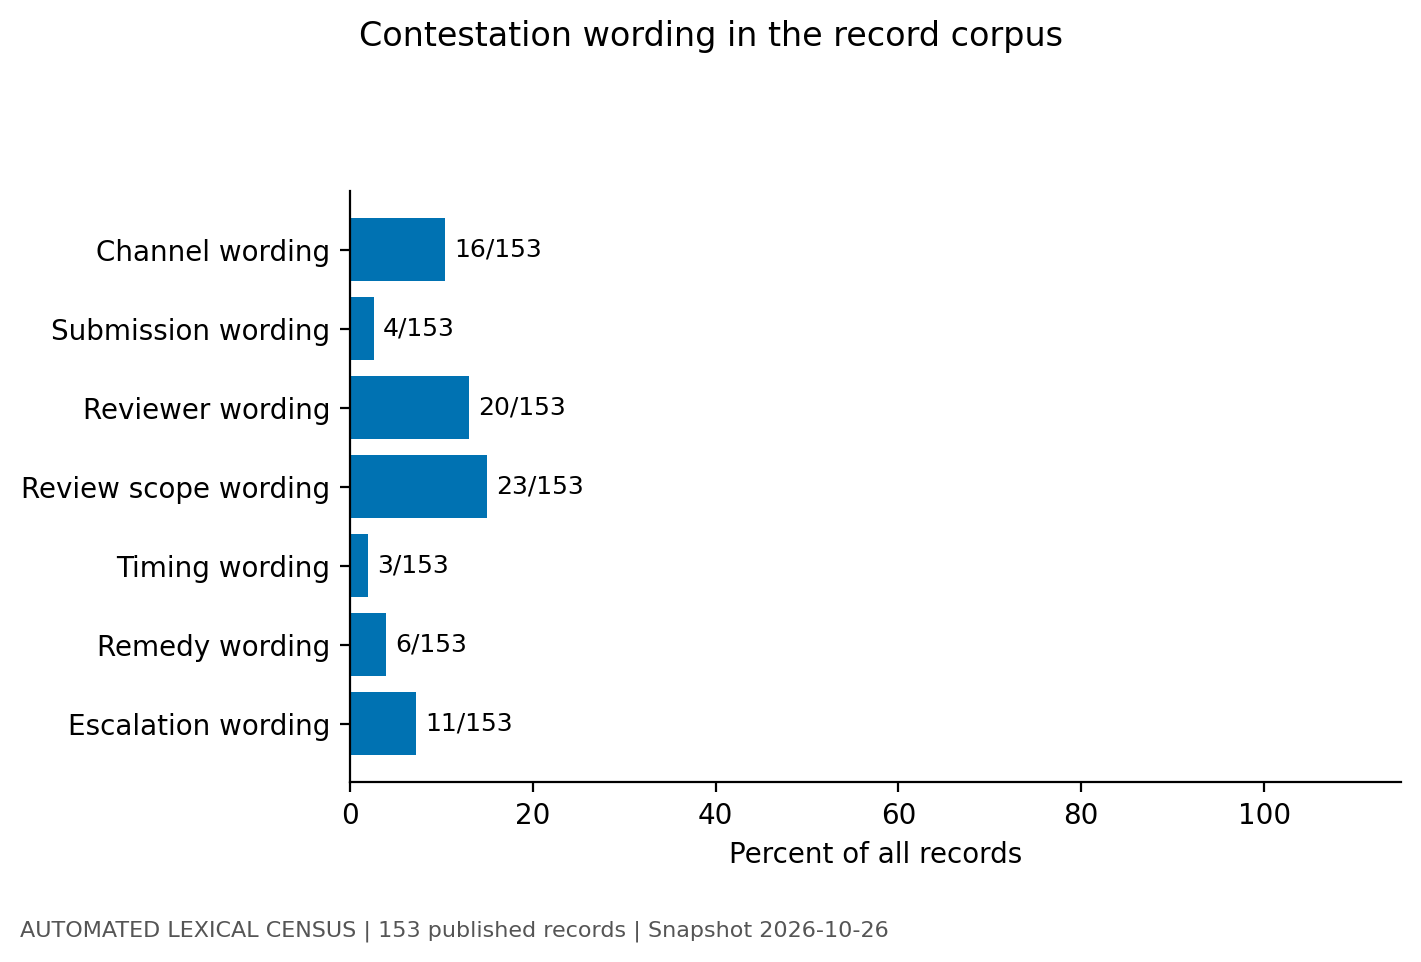

**RQ1_F2 — Nested contestation cue combinations**  
The ordering is an analytical intersection, not an observed appeal journey or causal funnel. It does not establish that a route works in practice.

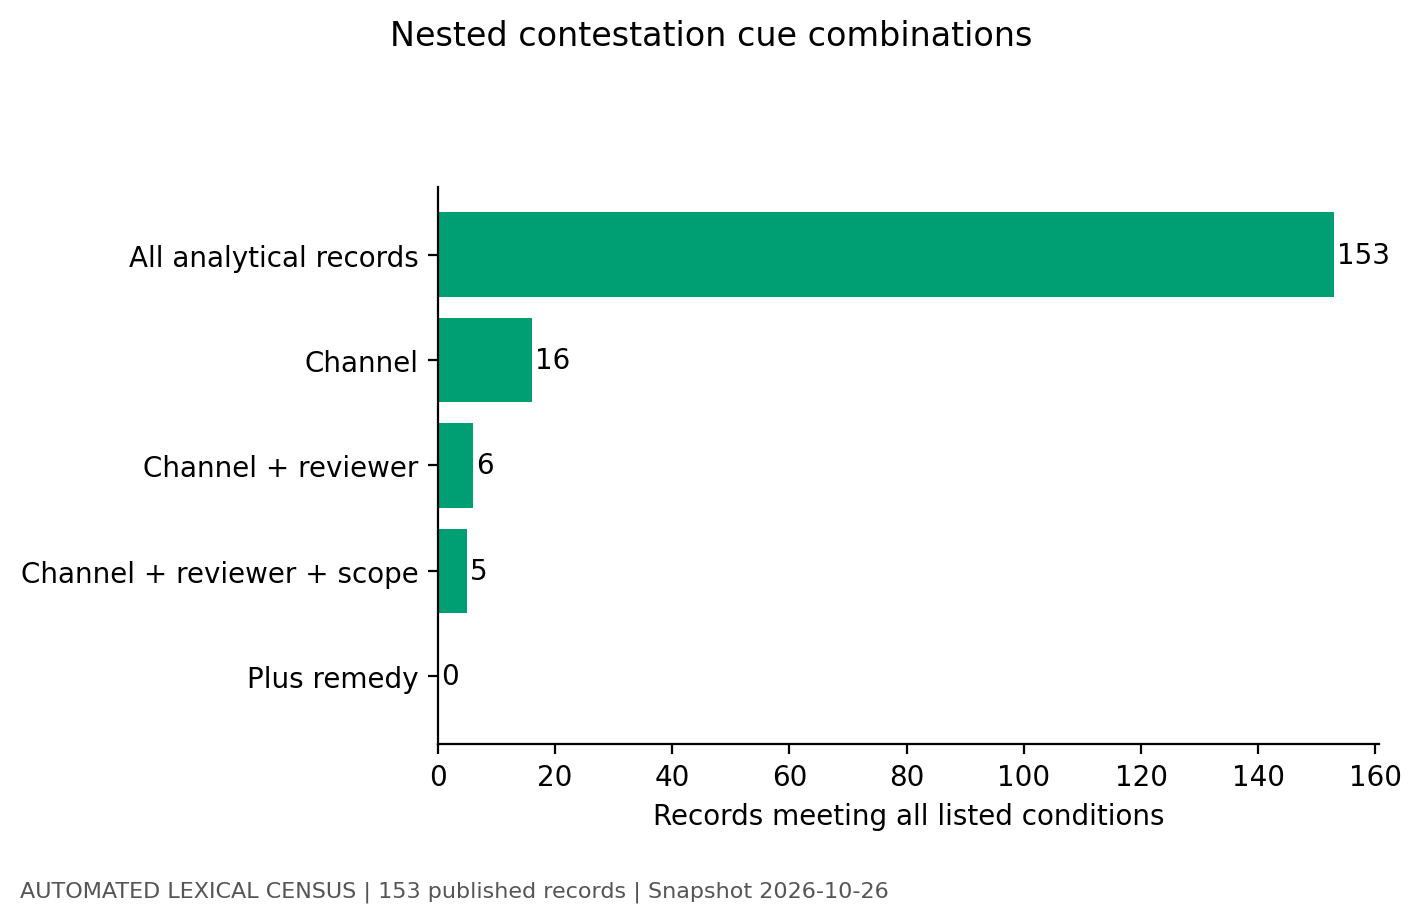

**RQ1_T1 — Corpus and lexical census denominator**  
AUTOMATED LEXICAL CENSUS | 153 published records. All published records in the frozen snapshot are included by design, including internal and general information tools.

,stage,records
0,Frozen published corpus,153
1,Included in lexical census,153
2,Excluded from lexical census,0


**RQ1_T2 — Ten most frequent lexical cue profiles**  
AUTOMATED LEXICAL CENSUS | 153 published records. Profiles retain the underlying disclosure states. Rows are sorted by frequency; omitted profiles remain in analysis_records.csv.

,channel,requirements,reviewer,scope,timing,remedy,escalation,records,percent_of_analytical_records
0,not_detected,not_detected,not_detected,not_detected,not_detected,not_detected,not_detected,113,73.856
1,not_detected,not_detected,not_detected,detected,not_detected,not_detected,not_detected,7,4.575
2,detected,not_detected,not_detected,not_detected,not_detected,not_detected,not_detected,5,3.268
3,not_detected,not_detected,detected,not_detected,not_detected,not_detected,not_detected,5,3.268
7,detected,detected,detected,detected,detected,not_detected,not_detected,2,1.307
9,detected,not_detected,detected,detected,not_detected,not_detected,detected,2,1.307
8,detected,not_detected,not_detected,detected,not_detected,not_detected,not_detected,2,1.307
6,not_detected,not_detected,detected,detected,not_detected,not_detected,detected,2,1.307
5,not_detected,not_detected,detected,not_detected,not_detected,not_detected,detected,2,1.307
4,not_detected,not_detected,not_detected,not_detected,not_detected,not_detected,detected,2,1.307


In [6]:
# M6 / RQ1 — Four outputs on procedural pathways
# Map element prevalence, nested requirements, the analytical denominator and common profiles.
profile=feature_profile(analysis)
fig,ax=plt.subplots(figsize=(7.2,4.7))
bars=ax.barh(profile.element,profile.percent,color=COLORS[0]);ax.invert_yaxis();ax.set_xlim(0,115)
ax.set_xlabel('Percent of all records' if MODE=='AI_ASSISTED_LEXICAL_CENSUS' else 'Percent of applicable records')
for bar,r in zip(bars,profile.itertuples()):
    if np.isfinite(r.percent):ax.text(r.percent+1,bar.get_y()+bar.get_height()/2,f'{r.positive}/{r.analysis_denominator}',va='center',fontsize=9)
fig_out('RQ1_F1','Contestation wording in the record corpus',fig,profile,
        'Numerators and denominators shown. Positives are lexical matches, not validated procedures; non-detection is not evidence of absence.')
steps=[('All analytical records',[]),('Channel',['channel']),('Channel + reviewer',['channel','reviewer']),
       ('Channel + reviewer + scope',['channel','reviewer','scope']),('Plus remedy',['channel','reviewer','scope','remedy'])]
chain=pd.DataFrame([{'requirement':name,'records':int(analysis[[f+'_n' for f in fs]].all(axis=1).sum()) if fs else len(analysis)} for name,fs in steps])
fig,ax=plt.subplots(figsize=(7.2,4.5));ax.barh(chain.requirement,chain.records,color=COLORS[2]);ax.invert_yaxis()
ax.set_xlabel('Records meeting all listed conditions')
for i,n in enumerate(chain.records):ax.text(n+.5,i,str(n),va='center')
fig_out('RQ1_F2','Nested contestation cue combinations',fig,chain,'The ordering is an analytical intersection, not an observed appeal journey or causal funnel. It does not establish that a route works in practice.')
flow=pd.DataFrame([{'stage':'Frozen published corpus','records':len(df)},
 {'stage':'Included in lexical census','records':len(analysis)},
 {'stage':'Excluded from lexical census','records':0}])
table_out('RQ1_T1','Corpus and lexical census denominator',flow,'All published records in the frozen snapshot are included by design, including internal and general information tools.')
patterns=(analysis[FEATURES].value_counts(dropna=False).rename('records').reset_index()
          .sort_values(['records']+FEATURES, ascending=[False]+[True]*len(FEATURES), kind='stable').head(10))
patterns['percent_of_analytical_records']=100*patterns.records/len(analysis)
table_out('RQ1_T2','Ten most frequent lexical cue profiles',patterns,'Profiles retain the underlying disclosure states. Rows are sorted by frequency; omitted profiles remain in analysis_records.csv.')

### M4 Answer revised RQ2 with four main outputs
RQ2. Which predefined appeals-wording categories occur across deployment stages and decision-role cue categories, and what source passages illustrate them?

**RQ2_F1 — Appeals wording and decision-role cues**  
Counts, not consistency judgments. Role and rationale groupings describe wording, not actual roles or consistency.

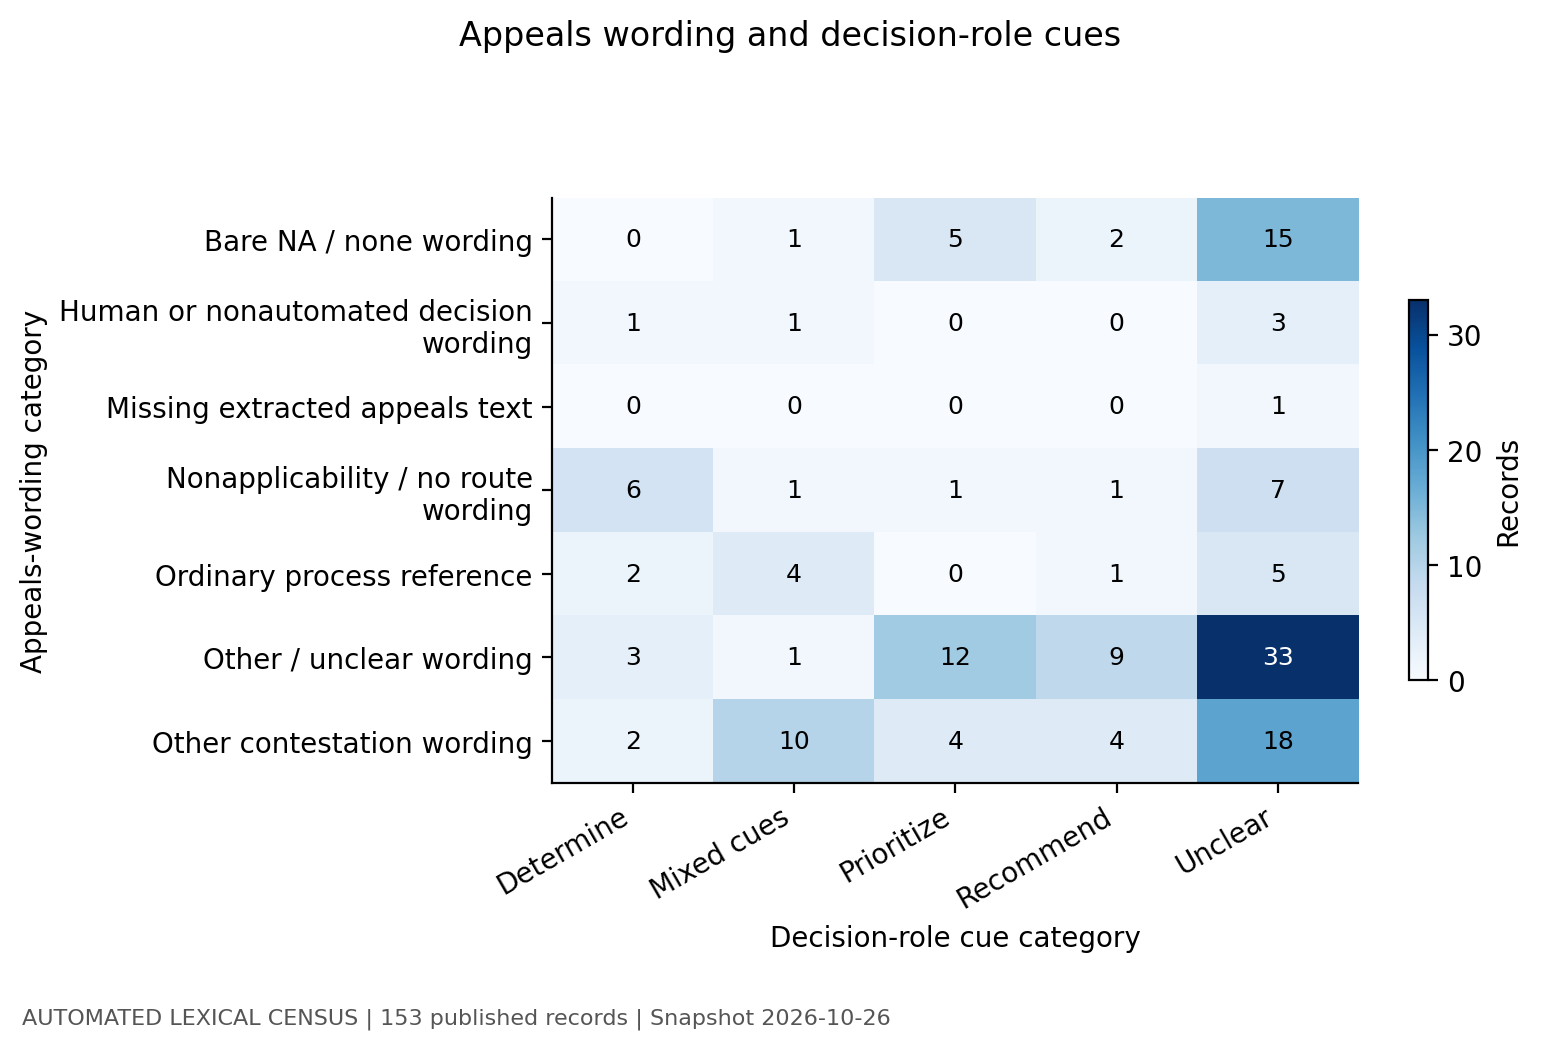

**RQ2_F2 — Appeals wording across deployment stages**  
Stage separates production disclosures from pilot, planned and retired systems; no maturity or causal inference.

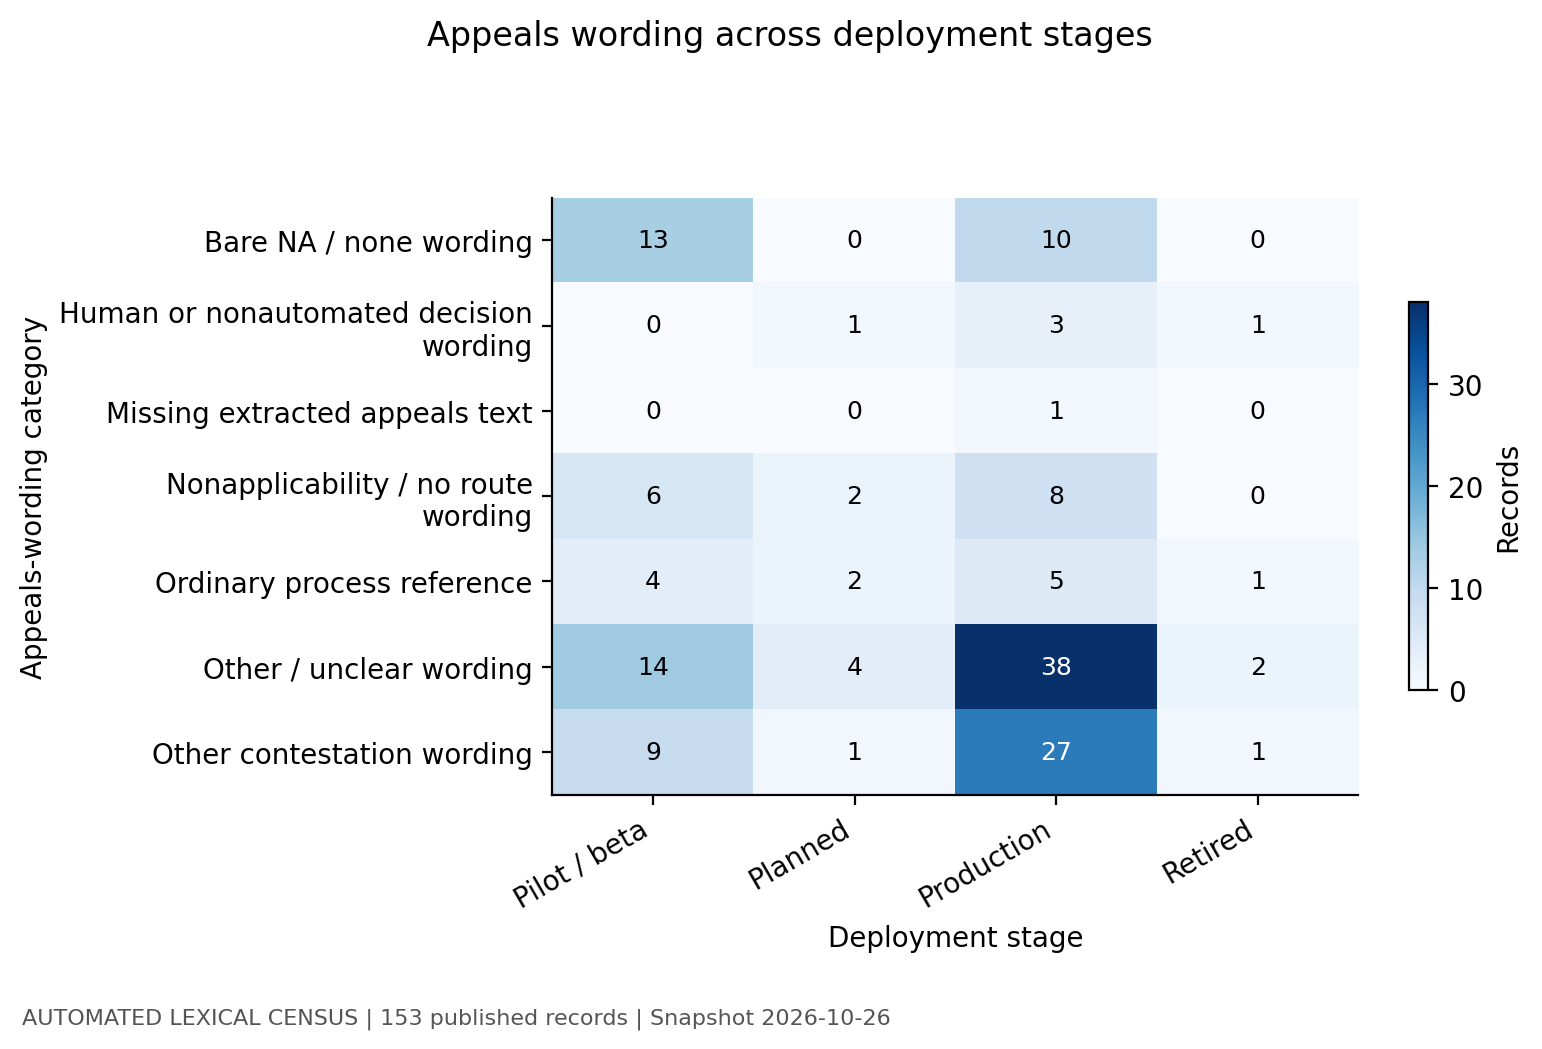

**RQ2_T1 — Appeals wording category prevalence**  
AUTOMATED LEXICAL CENSUS | 153 published records. Exclusive ordered wording categories; not legal consistency or validity judgments.

,rationale,records,percent
0,Bare NA / none wording,23,15.033
1,Human or nonautomated decision wording,5,3.268
2,Missing extracted appeals text,1,0.654
3,Nonapplicability / no route wording,16,10.458
4,Ordinary process reference,12,7.843
5,Other / unclear wording,58,37.908
6,Other contestation wording,38,24.837


**RQ2_T2 — Source-linked rationale audit cases**  
AUTOMATED LEXICAL CENSUS | 153 published records. One example per category, selected by lowest record ID. Complete extracted appeals and process fields are retained; the archived full record remains the primary source. Examples are not prevalence evidence.

,rationale,record_id,title,decision_role,appeals_excerpt,process_excerpt,source_url
0,Bare NA / none wording,07300799-85f5-4359-820a-fab3d81fbb9e,Ealing Council: Adult Social Care Annual Financial Expenditure Forecast,Unclear,N/A,Part of annual budget setting and advice to Senior Leadership Team at start of year.,https://www.gov.uk/algorithmic-transparency-records/ealing-council-adult-social-care-annual-financial-expenditure-forecast
1,Human or nonautomated decision wording,b9fea827-2b82-467c-b88c-8d57dfdf8f17,DWP: Conversational Platform,Unclear,This tool does not make any decisions and the caller has the option to be routed to a human agent if the wish if they have any additional needs,"The tool does not make any decisions, either the customer makes a decision to end the call after we have provided signposting information to alternative channels, or the call is routed to through to a human agent and the caller will discuss their query with them and the agent would follow their processes regarding decision making when required. The tool is integrated with the DWPs ‘Dynamic Trust Hub’ (DTH) and communicates via an Application Programming Interface (API). This is in the context of identifying and verifying a customer who is being routed through to an agent. Conversational Platform asks citizens a question from the ID&V list and relays that answer to DTH which replies with a ‘yes or no’ to indicate whether the answer is correct or incorrect. The Conversational Platform does not make any decisions in this process either.",https://www.gov.uk/algorithmic-transparency-records/dwp-conversational-platform
2,Missing extracted appeals text,4bb5c16e-4f8c-4833-8dce-d929d11803fc,DBT: Find Exporters,Unclear,,"The tool provides users with data-driven insights on a company’s propensity to export, which provides the user with future prospects to engage. This information complements and integrates with many further insights from other sources available to the users to make the best-informed decisions on which companies to engage next.",https://www.gov.uk/algorithmic-transparency-records/dbt-find-exporters
3,Nonapplicability / no route wording,130524a1-4b53-420e-8867-fa484245fe9a,DESNZ: Find ways to save energy in your home,Recommend,"No Formal Appeals Process: There is no formal appeals process for the advice or recommendations provided directly by the service. If a member of the public wishes to challenge a decision about eligibility for a government scheme, they must follow the appeals process of the relevant scheme administrator. For issues with energy efficiency ratings (EPCs), there is a defined process involving the assessor and their accreditation body. Feedback Mechanism: Members of the public can provide feedback on the service via a Microsoft form. This feedback is used to improve the service but does not constitute a formal appeals process.",The information provided is advisory for users and does not form part of a larger process. The output of this tool is reviewed by the user that fills out the form. They can use a contact form to inform DESNZ if the information appears inaccurate,https://www.gov.uk/algorithmic-transparency-records/desnz-find-ways-to-save-energy-in-your-home
4,Ordinary process reference,00de9758-2f8c-4adb-9c9a-ff57cb2d50a0,DVLA: Drivers Medical Casework System,Recommend,"There are standard existing appeals procedures in place that will be used regardless of systems used. The licence holder (customer) is sent a letter detailing the licensing decision, which includes details on their rights of an appeal. If a licence holder has extra medical evidence thats not been considered as part of the licensing decision they can appeal in writing directly to DVLA for further consideration. If a driver appeals with no extra medical evidence, they must contact their local magistrate court in England and Wales, or Sheriff’s court in Scotland, and notify DVLA of their intention to appeal. This right in relation to automated decisio

In [7]:
# M7 / RQ2 — Four outputs on appeals rationales
# Compare rationale categories with decision role and stage, then retain exact passages for consistency review.
tab=pd.crosstab(analysis.rationale,analysis.decision_role)
fig=heatmap_table(tab,'','Decision-role cue category','Appeals-wording category')
fig_out('RQ2_F1','Appeals wording and decision-role cues',fig,tab.reset_index(),'Counts, not consistency judgments. Role and rationale groupings describe wording, not actual roles or consistency.')
tab2=pd.crosstab(analysis.rationale,analysis.stage)
fig=heatmap_table(tab2,'','Deployment stage','Appeals-wording category')
fig_out('RQ2_F2','Appeals wording across deployment stages',fig,tab2.reset_index(),'Stage separates production disclosures from pilot, planned and retired systems; no maturity or causal inference.')
rationale=analysis.groupby('rationale').size().rename('records').reset_index()
rationale['percent']=100*rationale.records/len(analysis)
table_out('RQ2_T1','Appeals wording category prevalence',rationale,'Exclusive ordered wording categories; not legal consistency or validity judgments.')
cases=[]
for category,g in analysis.sort_values('record_id').groupby('rationale',sort=True):
    r=g.iloc[0]
    cases.append({'rationale':category,'record_id':r.record_id,'title':r.title,'decision_role':r.decision_role,
       'appeals_excerpt':str(r.appeals_text),
       'process_excerpt':str(r.process_text),'source_url':r.source_url})
table_out('RQ2_T2','Source-linked rationale audit cases',pd.DataFrame(cases),
          'One example per category, selected by lowest record ID. Complete extracted appeals and process fields are retained; the archived full record remains the primary source. Examples are not prevalence evidence.')

### M4 Answer revised RQ3 with four main outputs
RQ3. How do contestation-related cue profiles vary across automatically assigned decision-role cue categories and stage or template subsets?

**RQ3_F1 — Contestation cue profiles by decision-role cues**  
Percentages use all published records within each role-cue category; this grouping has not been validated as actual decision influence. Sizes appear in RQ3_T1.

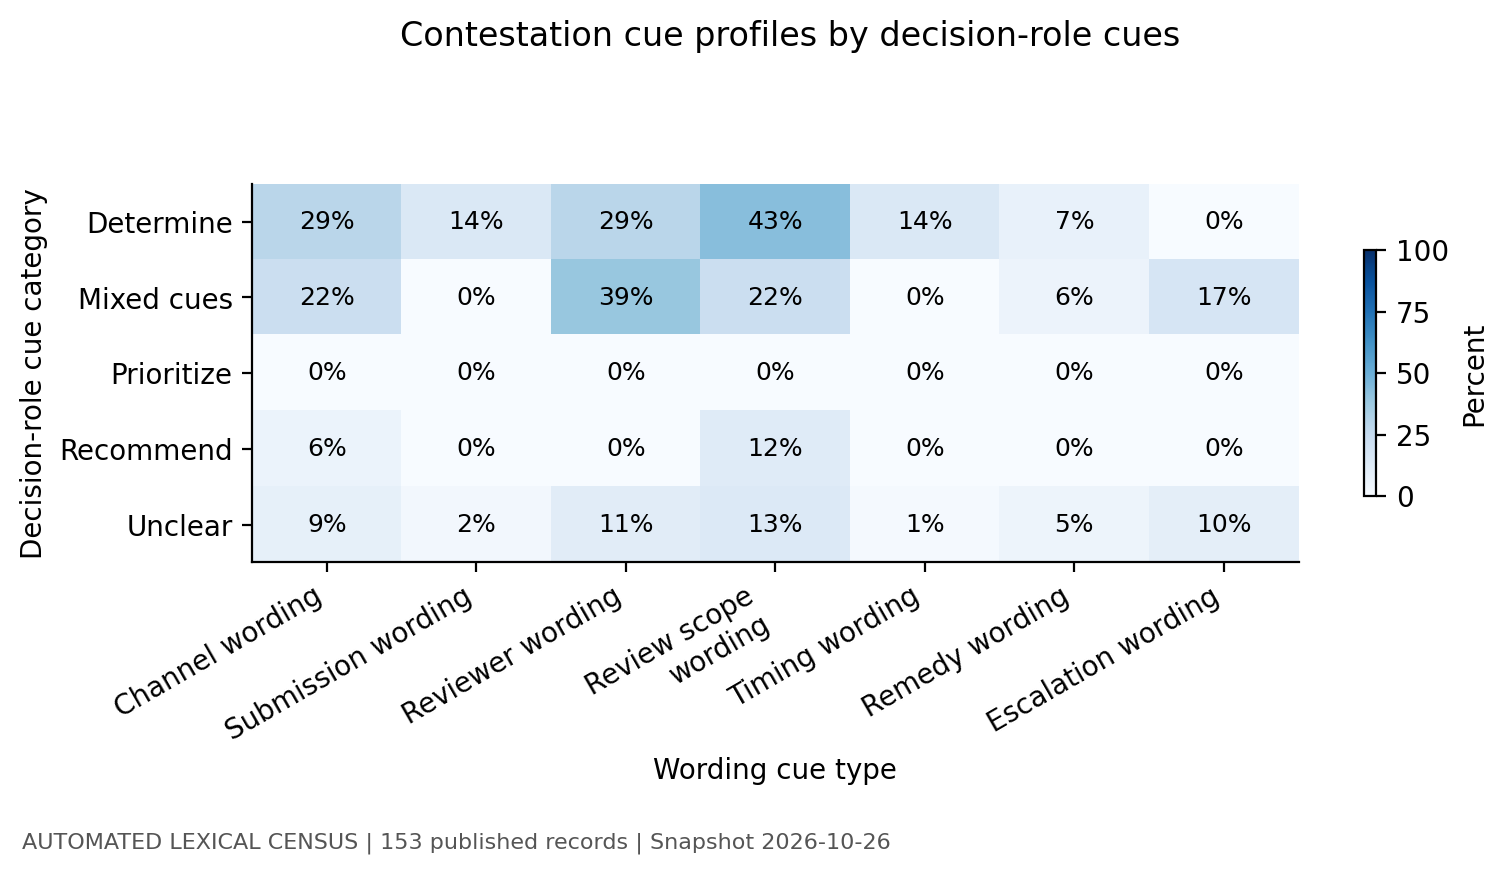

**RQ3_F2 — Cue-count distributions by decision-role cues**  
Points are records; horizontal bars are medians. Jitter is seeded and has no substantive meaning.

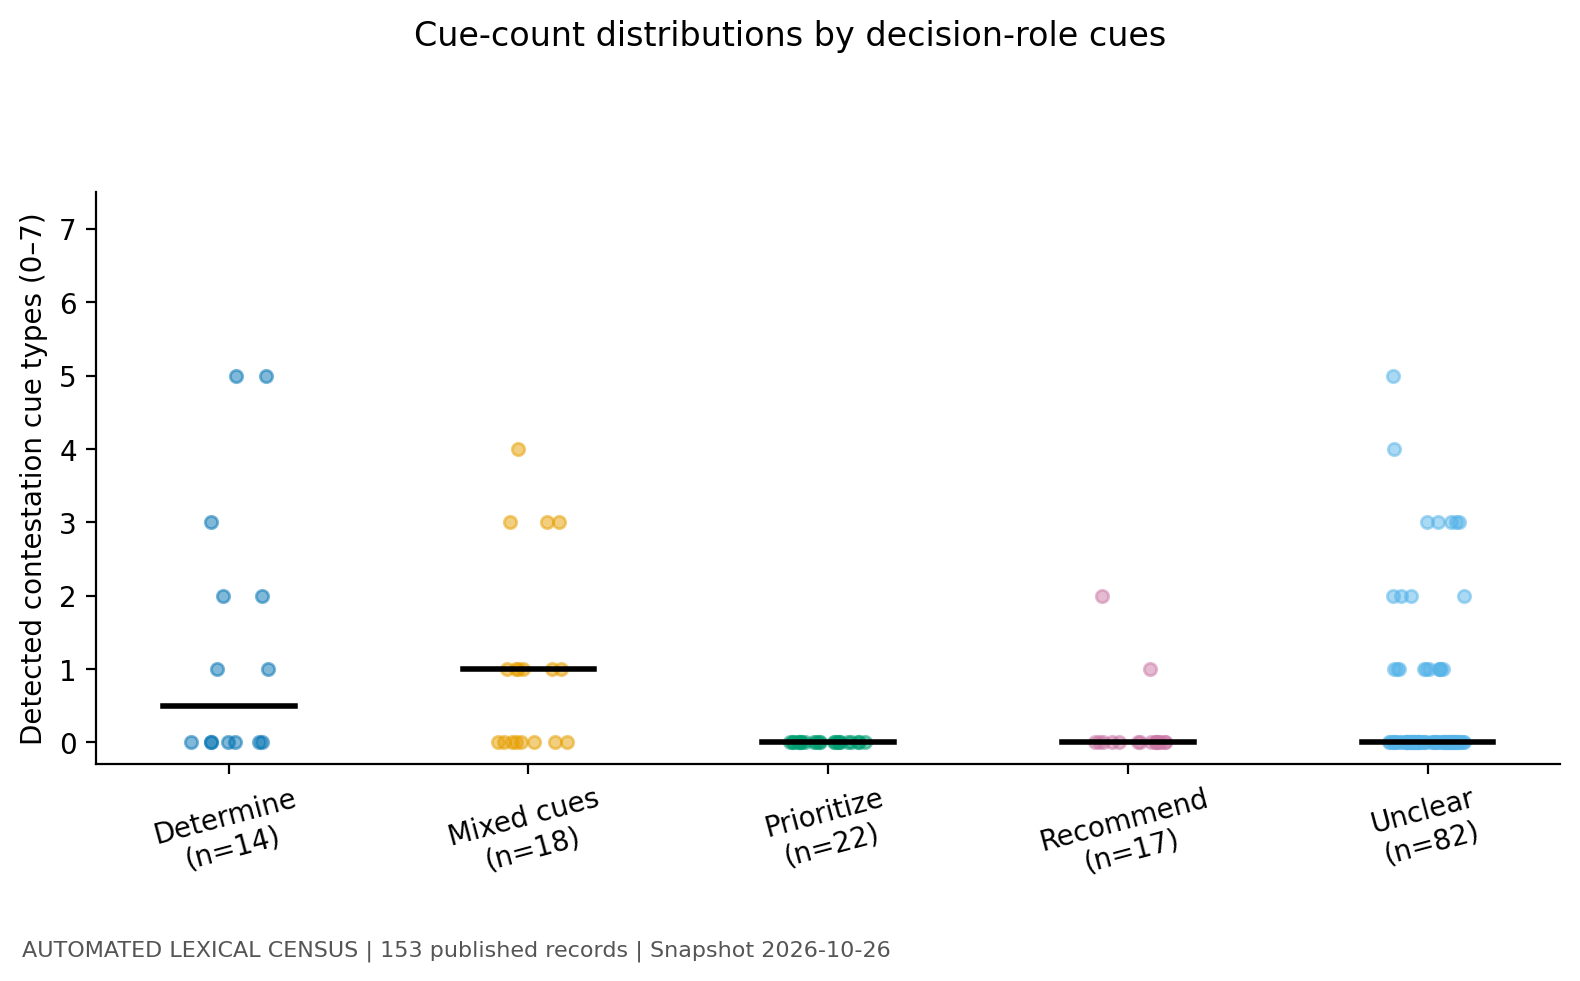

**RQ3_T1 — Decision-role cue group composition**  
AUTOMATED LEXICAL CENSUS | 153 published records. Read group comparisons alongside stage, template and document-length composition. Unclear/mixed groups are retained.

,decision_role,n,median_elements,median_words,production_n,v3_n,v4_n
0,Determine,14,0.500,2820.000,9,7,7
1,Mixed cues,18,1.000,3327.000,10,11,5
2,Prioritize,22,0.000,2047.500,15,13,8
3,Recommend,17,0.000,2453.000,8,10,4
4,Unclear,82,0.000,2308.500,50,47,30


**RQ3_T2 — Stage and template sensitivity comparisons**  
AUTOMATED LEXICAL CENSUS | 153 published records. Subsets overlap; rows are not independent experiments. No causal estimates or significance claims.

,subset,decision_role,n,median_elements,mean_elements,median_words,interpretation
0,All,Determine,14,0.500,1.357,2820.000,Descriptive comparison
1,All,Mixed cues,18,1.000,1.056,3327.000,Descriptive comparison
2,All,Prioritize,22,0.000,0.000,2047.500,Descriptive comparison
3,All,Recommend,17,0.000,0.176,2453.000,Descriptive comparison
4,All,Unclear,82,0.000,0.512,2308.500,Descriptive comparison
5,Production,Determine,9,2.000,2.000,2889.000,Descriptive comparison
6,Production,Mixed cues,10,1.000,1.400,3484.000,Descriptive comparison
7,Production,Prioritize,15,0.000,0.000,1991.000,Descriptive comparison
8,Production,Recommend,8,0.000,0.000,3493.500,Descriptive comparison
9,Production,Unclear,50,0.000,0.480,2257.000,Descriptive comparison


In [8]:
# M8 / RQ3 — Four outputs on decision roles
# Compare procedural profiles and distributions, with stage and template sensitivity checks.
role_rows=[]
for role,g in analysis.groupby('decision_role',sort=True):
    t=feature_profile(g);t['decision_role']=role;role_rows.append(t)
role_profiles=pd.concat(role_rows,ignore_index=True)
tab=role_profiles.pivot(index='decision_role',columns='element',values='percent').reindex(columns=[LABELS[f] for f in FEATURES])
fig=heatmap_table(tab,'','Wording cue type','Decision-role cue category',percent=True)
fig_out('RQ3_F1','Contestation cue profiles by decision-role cues',fig,role_profiles,'Percentages use all published records within each role-cue category; this grouping has not been validated as actual decision influence. Sizes appear in RQ3_T1.')
groups=list(analysis.groupby('decision_role',sort=True))
fig,ax=plt.subplots(figsize=(8,4.8));rng=np.random.default_rng(SEED)
for i,(role,g) in enumerate(groups):
    ax.scatter(np.full(len(g),i)+rng.uniform(-.13,.13,len(g)),g.element_count,alpha=.5,s=20,color=COLORS[i%len(COLORS)])
    ax.plot([i-.22,i+.22],[g.element_count.median()]*2,color='black',lw=2)
ax.set_xticks(range(len(groups)),[f'{r}\n(n={len(g)})' for r,g in groups],rotation=15)
ax.set_ylabel(COUNT_LABEL);ax.set_ylim(-.3,7.5)
fig_out('RQ3_F2','Cue-count distributions by decision-role cues',fig,
        analysis[['record_id','decision_role','element_count']],'Points are records; horizontal bars are medians. Jitter is seeded and has no substantive meaning.')
summary=[]
for role,g in groups:
    summary.append({'decision_role':role,'n':len(g),'median_elements':g.element_count.median(),
       'median_words':g.words.median(),'production_n':int(g.stage.eq('Production').sum()),
       'v3_n':int(g.version.eq('v3').sum()),'v4_n':int(g.version.eq('v4').sum())})
table_out('RQ3_T1','Decision-role cue group composition',pd.DataFrame(summary),'Read group comparisons alongside stage, template and document-length composition. Unclear/mixed groups are retained.')
sens=[]
SUBSETS={'All':analysis,'Production':analysis[analysis.stage.eq('Production')],
         'Template v3':analysis[analysis.version.eq('v3')],'Template v4':analysis[analysis.version.eq('v4')]}
for subset,g0 in SUBSETS.items():
    for role,g in g0.groupby('decision_role'):
        sens.append({'subset':subset,'decision_role':role,'n':len(g),'median_elements':g.element_count.median(),
                     'mean_elements':g.element_count.mean(),'median_words':g.words.median(),
                     'interpretation':'Sparse group: descriptive only' if len(g)<5 else 'Descriptive comparison'})
table_out('RQ3_T2','Stage and template sensitivity comparisons',pd.DataFrame(sens),'Subsets overlap; rows are not independent experiments. No causal estimates or significance claims.')

### M4 Answer revised RQ4 with four main outputs
RQ4. How is archived record length associated with the number of detected contestation-related cue types, and which similarly long records contrast?

**RQ4_F1 — Disclosure length and contestation cues**  
A larger document offers more opportunities for lexical matches. This association does not validate usefulness, quality or causality.

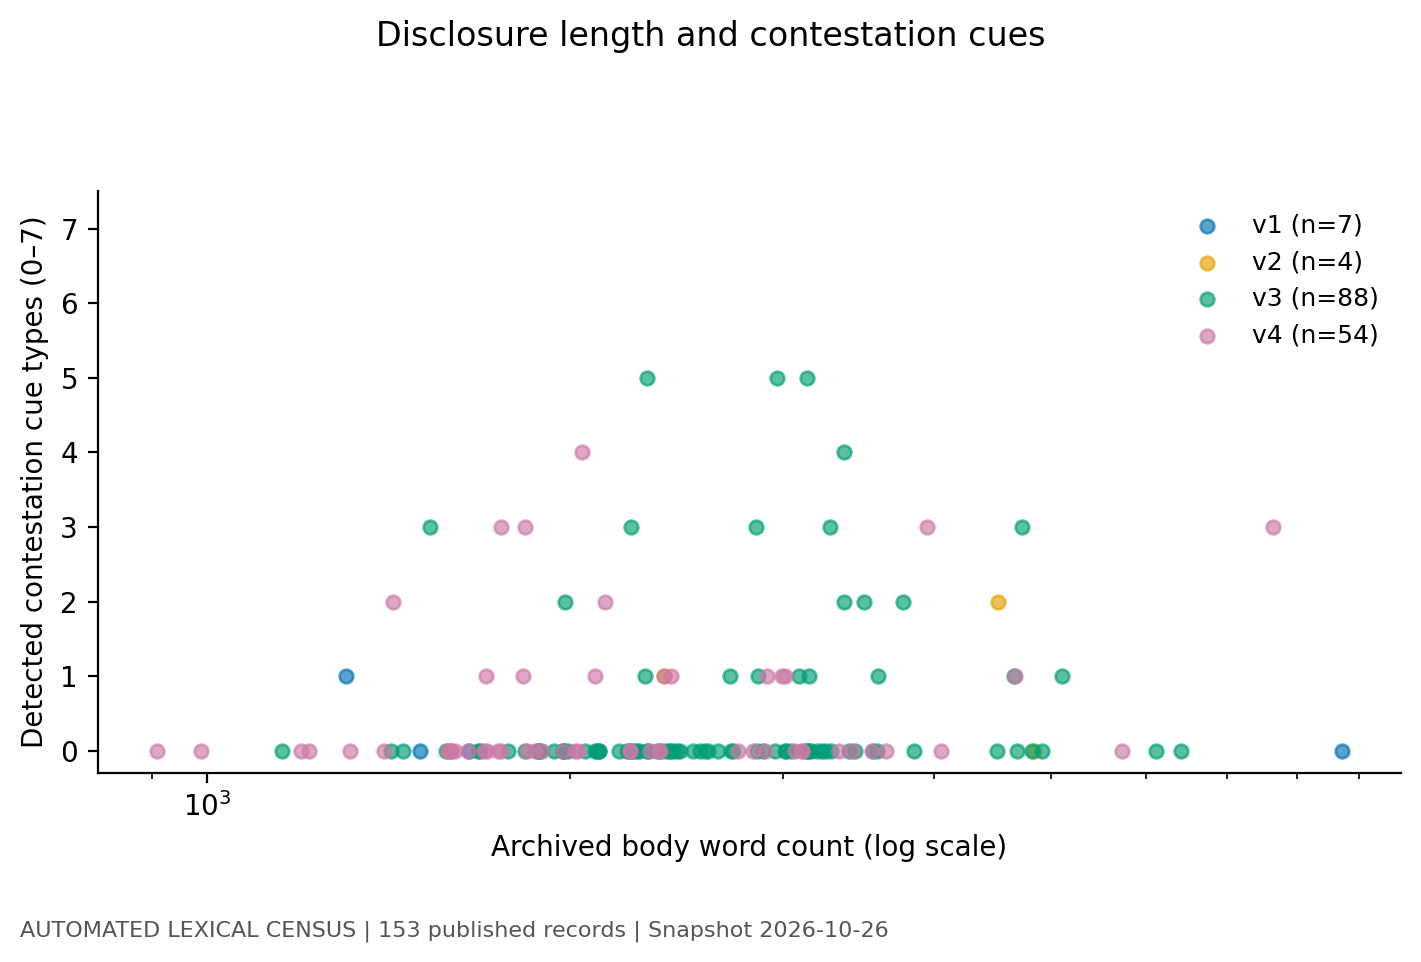

**RQ4_F2 — Contestation cues within disclosure-length bands**  
Bands are empirical quantiles, with ties allowed to reduce the number of bands. Dots show each record; boxes summarize distributions.

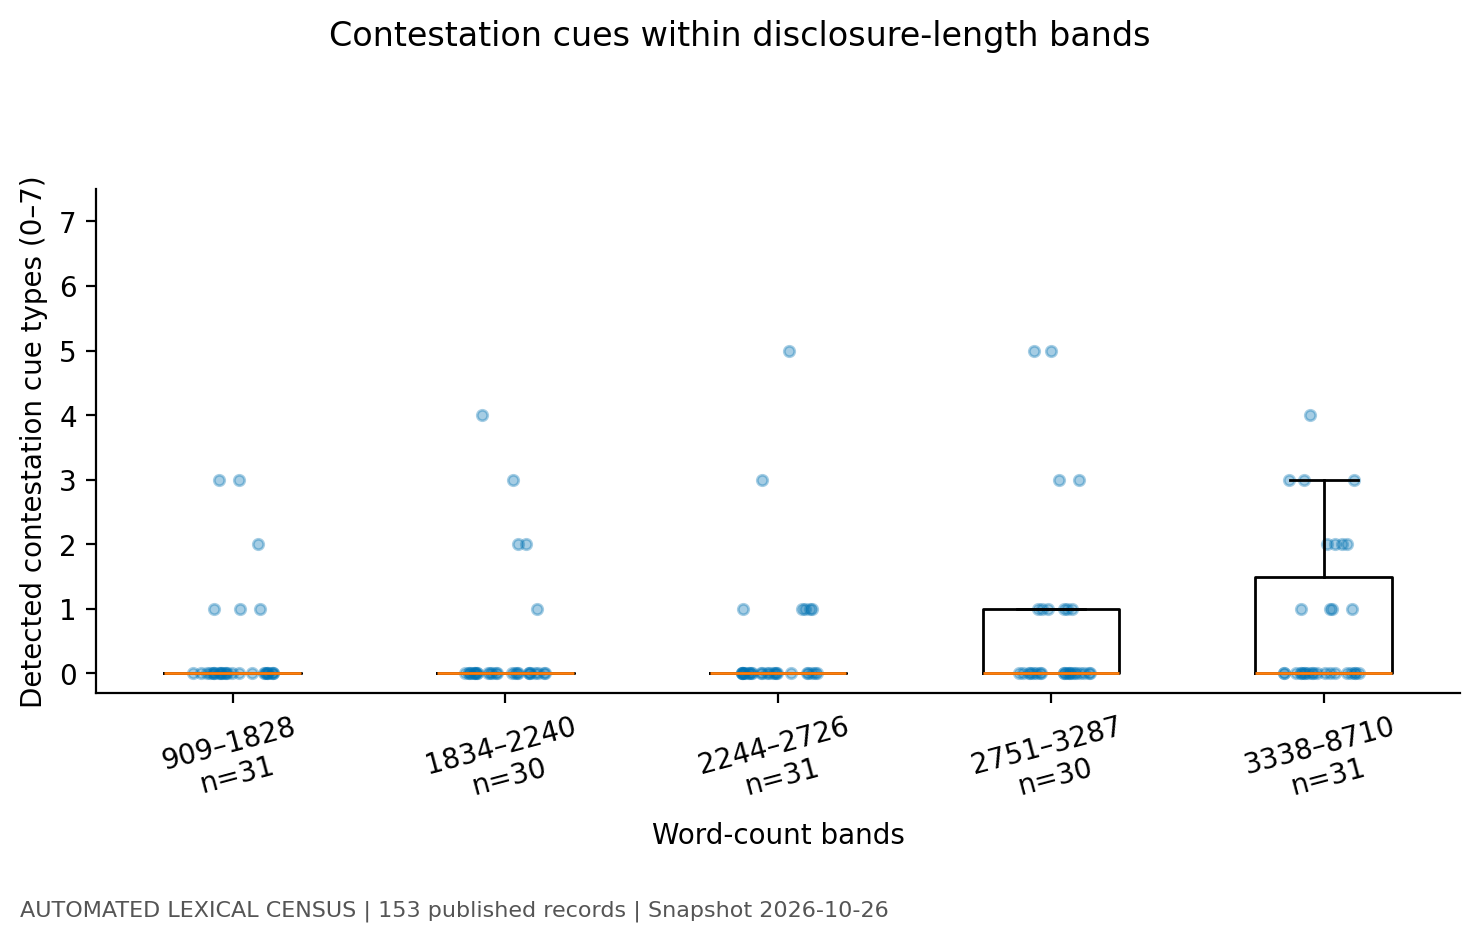

**RQ4_T1 — Disclosure-length association sensitivity**  
AUTOMATED LEXICAL CENSUS | 153 published records. No p-values are used for this finite, selectively published registry census. Ties receive average ranks.

,subset,n,spearman_rho,status
0,All,153,0.166,Descriptive rank correlation; no population p-value
1,Production,92,0.208,Descriptive rank correlation; no population p-value
2,Template v3,88,0.246,Descriptive rank correlation; no population p-value
3,Template v4,54,0.174,Descriptive rank correlation; no population p-value


**RQ4_T2 — Similar-length contrasting record pairs**  
AUTOMATED LEXICAL CENSUS | 153 published records. Greedy non-overlapping pairs: largest element gap first, then closest length, then record ID. Purposive examples, not causal matching or representative effect estimates.

,record_a,id_a,words_a,elements_a,record_b,id_b,words_b,elements_b,word_ratio,element_gap,url_a,url_b
0,National Highways: Highways Webchat,a2a70309-6052-4258-b536-6badd03af5ea,2313,0,DESNZ: Green Deal Reduction Calculator,c1a7c26b-dc6f-4319-9883-ddc31369d9dd,2313,5,1.000,5,https://www.gov.uk/algorithmic-transparency-records/national-highways-highways-webchat,https://www.gov.uk/algorithmic-transparency-records/desnz-green-deal-reduction-calculator
1,DVLA: Contact Centre Chatbot service,25911e60-06fe-4bab-9728-04ceeb43d693,3139,0,Student Loans Company: Postgraduate Assessment Rules,72ecfbc8-841c-4f69-8a7e-9c16ae13d4fe,3142,5,1.001,5,https://www.gov.uk/algorithmic-transparency-records/dvla-contact-centre-chatbot-service,https://www.gov.uk/algorithmic-transparency-records/student-loans-company-postgraduate-assessment-rules
2,Student Loans Company: Advanced Learning Loans Assessment Rules,bd959c23-283b-4b24-bf73-59f7aff3c97a,2966,5,Oak National Academy: Aila (Oak's AI Lesson Assistant),fc2b6d75-a5fb-4204-a77a-7b0808225bd1,2957,0,1.003,5,https://www.gov.uk/algorithmic-transparency-records/slc-advanced-learning-loans-assessment-rules,https://www.gov.uk/algorithmic-transparency-records/oak-national-academy-aila-oaks-ai-lesson-assistant
3,Ealing Council: Adult Social Care Annual Financial Expenditure Forecast,07300799-85f5-4359-820a-fab3d81fbb9e,2056,0,DfT: EV Chargepoint Grant Photos Fraud Tool,c98af674-d58f-463f-815e-317c8e3d0f9b,2046,4,1.005,4,https://www.gov.uk/algorithmic-transparency-records/ealing-council-adult-social-care-annual-financial-expenditure-forecast,https://www.gov.uk/algorithmic-transparency-records/ev-chargepoint-grant-photos-fraud-tool
4,DWP: Child Maintenance Service (CMS) - Predictive Analytics Compliance,308ce38a-847f-43ce-ad37-ff65821d9f94,3371,4,DBT: Business Intelligence (BI) Subject Tagger,5297e2af-a3d2-4b0b-834b-39b5d20e44eb,3401,0,1.009,4,https://www.gov.uk/algorithmic-transparency-records/dwp-child-maintenance-service-cms-predictive-analytics-compliance,https://www.gov.uk/algorithmic-transparency-records/dbt-business-intelligence-bi-subject-tagger
5,LGSCO: LGSCO Chatbot,1d271a04-f762-4695-a442-15131352d27a,1834,3,BDUK: Project Gigabit Voucher Eligibility Engine,e79acd78-c31d-4eb6-aa88-701021a9aafe,1834,0,1.000,3,https://www.gov.uk/algorithmic-transparency-records/lgsco-lgsco-chatbot,https://www.gov.uk/algorithmic-transparency-records/bduk-project-gigabit-voucher-eligibility-engine


In [9]:
# M9 / RQ4 — Four outputs on length and procedural specificity
# Assess rank associations and reproducible contrasting cases without assuming the rubric is superior.
fig,ax=plt.subplots(figsize=(7.2,4.7))
for i,(version,g) in enumerate(analysis.groupby('version',sort=True)):
    ax.scatter(g.words,g.element_count,label=f'{version} (n={len(g)})',alpha=.65,s=24,color=COLORS[i])
ax.set_xscale('log');ax.set_xlabel('Archived body word count (log scale)');ax.set_ylabel(COUNT_LABEL);ax.set_ylim(-.3,7.5)
ax.legend(frameon=False,fontsize=9)
fig_out('RQ4_F1','Disclosure length and contestation cues',fig,
        analysis[['record_id','words','element_count','version','stage']],
        'A larger document offers more opportunities for lexical matches. This association does not validate usefulness, quality or causality.')
banded=analysis.copy()
banded['length_band']=pd.qcut(banded.words,q=min(5,banded.words.nunique()),duplicates='drop')
bands=list(banded.groupby('length_band',observed=True,sort=True))
fig,ax=plt.subplots(figsize=(7.5,4.6))
ax.boxplot([g.element_count for _,g in bands],positions=range(1,len(bands)+1),showfliers=False)
rng=np.random.default_rng(SEED)
for i,(_,g) in enumerate(bands,1):ax.scatter(i+rng.uniform(-.15,.15,len(g)),g.element_count,s=14,alpha=.35,color=COLORS[0])
ax.set_xticks(range(1,len(bands)+1),[f'{int(g.words.min())}–{int(g.words.max())}\nn={len(g)}' for _,g in bands],rotation=15)
ax.set_xlabel('Word-count bands');ax.set_ylabel(COUNT_LABEL);ax.set_ylim(-.3,7.5)
band_export=banded[['record_id','words','length_band','element_count']].copy();band_export['length_band']=band_export.length_band.astype(str)
fig_out('RQ4_F2','Contestation cues within disclosure-length bands',fig,band_export,
        'Bands are empirical quantiles, with ties allowed to reduce the number of bands. Dots show each record; boxes summarize distributions.')
assoc=[]
for subset,g in SUBSETS.items():
    ok=len(g)>=5 and g.words.nunique()>1 and g.element_count.nunique()>1
    rho=g.words.rank(method='average').corr(g.element_count.rank(method='average')) if ok else np.nan
    assoc.append({'subset':subset,'n':len(g),'spearman_rho':rho,
                  'status':'Descriptive rank correlation; no population p-value' if ok else 'Not estimable: small n or constant values'})
table_out('RQ4_T1','Disclosure-length association sensitivity',pd.DataFrame(assoc),
          'No p-values are used for this finite, selectively published registry census. Ties receive average ranks.')
pairs=[]
rows=list(analysis.sort_values('record_id').itertuples())
for i,a0 in enumerate(rows):
    for b0 in rows[i+1:]:
        ratio=max(a0.words,b0.words)/min(a0.words,b0.words)
        diff=abs(a0.element_count-b0.element_count)
        if ratio<=1.10 and diff>=2:
            pairs.append((diff,ratio,a0,b0))
pairs.sort(key=lambda z:(-z[0],z[1],z[2].record_id,z[3].record_id));used=set();chosen=[]
for gap,ratio,a0,b0 in pairs:
    if a0.record_id in used or b0.record_id in used:continue
    chosen.append({'record_a':a0.title,'id_a':a0.record_id,'words_a':a0.words,'elements_a':a0.element_count,
       'record_b':b0.title,'id_b':b0.record_id,'words_b':b0.words,'elements_b':b0.element_count,
       'word_ratio':ratio,'element_gap':gap,'url_a':a0.source_url,'url_b':b0.source_url})
    used.update([a0.record_id,b0.record_id])
    if len(chosen)==6:break
pair_table=pd.DataFrame(chosen) if chosen else pd.DataFrame([{'status':'No pairs met predeclared 10% length and two-element-gap criteria'}])
table_out('RQ4_T2','Similar-length contrasting record pairs',pair_table,
          'Greedy non-overlapping pairs: largest element gap first, then closest length, then record ID. Purposive examples, not causal matching or representative effect estimates.')

### M4 Answer revised RQ5 with four main outputs
RQ5. How do routine-oversight cues and affected-person review cues co-occur in the published records?

**RQ5_F1 — Routine oversight and affected-person review cues**  
Detection states denote predefined lexical patterns. A not_detected state is not proof that review is unavailable.

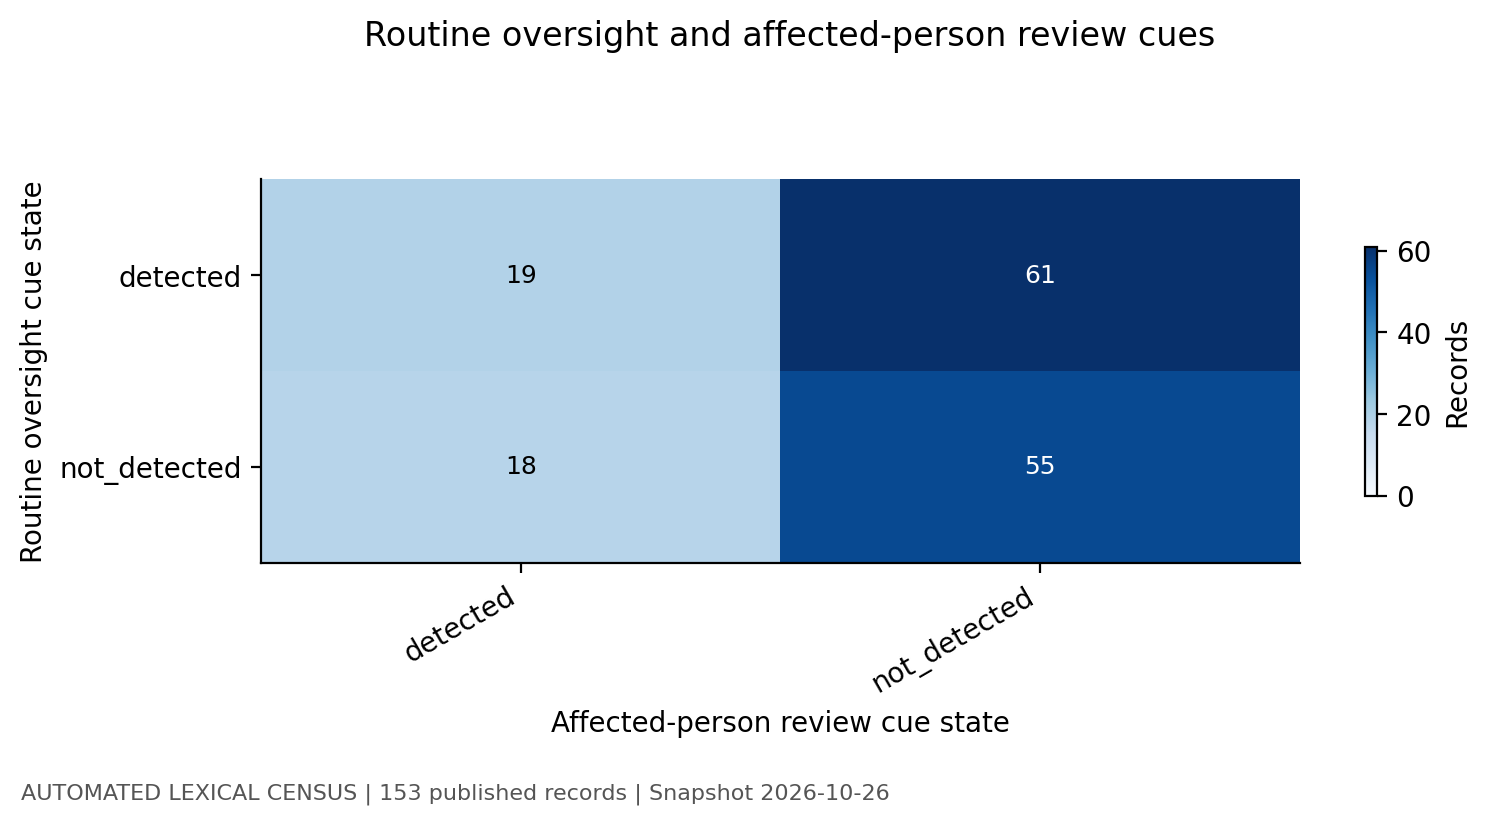

**RQ5_F2 — Contestation cues across oversight configurations**  
Configurations list routine oversight first and citizen review second. Shared source text may generate correlated cues; no causal interpretation.

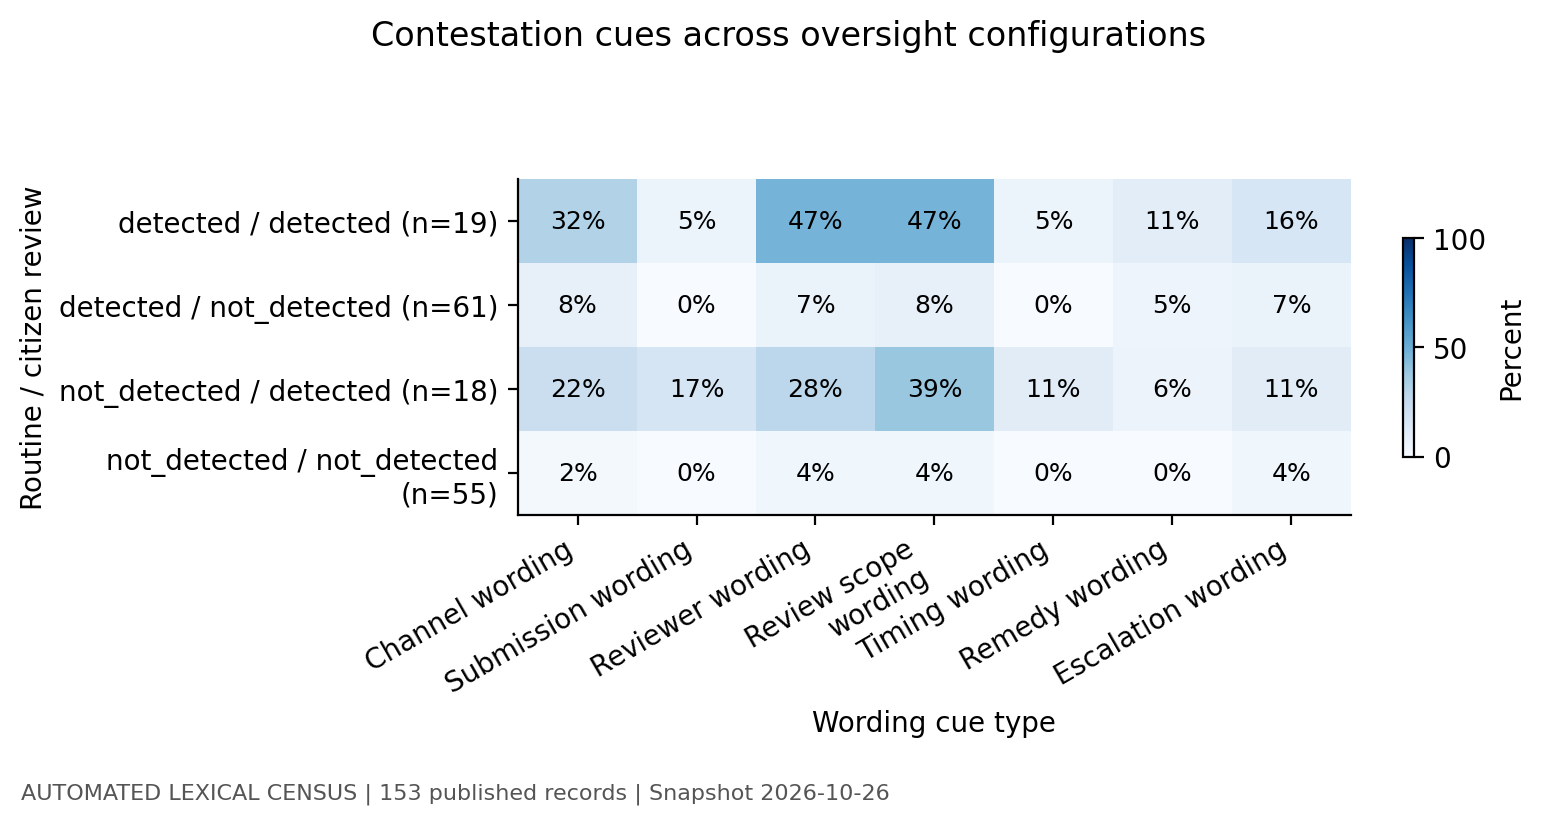

**RQ5_T1 — Affected-person review cues conditional on oversight cues**  
AUTOMATED LEXICAL CENSUS | 153 published records. Denominators include all records in each cue state. This is a wording census, not an applicability-adjusted safeguard estimate.

,routine_oversight,n,citizen_review_positive,analysis_denominator,citizen_review_percent,median_procedural_elements
0,detected,80,19,80,23.750,0.000
1,not_detected,73,18,73,24.658,0.000


**RQ5_T2 — Evidence for oversight configurations**  
AUTOMATED LEXICAL CENSUS | 153 published records. One case per observed configuration, selected by lowest record ID. Non-detection text is an analysis status, not a quotation or an absence finding.

,configuration,record_id,title,oversight_evidence,citizen_review_evidence,source_url
0,detected / detected,00de9758-2f8c-4adb-9c9a-ff57cb2d50a0,DVLA: Drivers Medical Casework System,Licensing decisions to the Drivers Medical caseworker.,"The licence holder (customer) is sent a letter detailing the licensing decision, which includes details on their rights of an appeal.",https://www.gov.uk/algorithmic-transparency-records/dvla-drivers-medical-casework-system
1,detected / not_detected,030b3ec1-5111-4abb-b51c-6dad093b2d99,DfE: Correspondence Drafter,"The tool will then provide a complete response output, DfE staff then review that output for any mistakes, issues and ways it could be improved.",No lexical cue detected; inspect the complete record.,https://www.gov.uk/algorithmic-transparency-records/dfe-correspondence-drafter
2,not_detected / detected,130524a1-4b53-420e-8867-fa484245fe9a,DESNZ: Find ways to save energy in your home,No lexical cue detected; inspect the complete record.,"If a member of the public wishes to challenge a decision about eligibility for a government scheme, they must follow the appeals process of the relevant scheme administrator.",https://www.gov.uk/algorithmic-transparency-records/desnz-find-ways-to-save-energy-in-your-home
3,not_detected / not_detected,07300799-85f5-4359-820a-fab3d81fbb9e,Ealing Council: Adult Social Care Annual Financial Expenditure Forecast,No lexical cue detected; inspect the complete record.,No lexical cue detected; inspect the complete record.,https://www.gov.uk/algorithmic-transparency-records/ealing-council-adult-social-care-annual-financial-expenditure-forecast


In [10]:
# M10 / RQ5 — Four outputs on oversight versus individual review
# Compare distinct oversight arrangements and retain evidence for evaluating ambiguous cases.
joint=pd.crosstab(analysis.routine_oversight,analysis.citizen_review)
fig=heatmap_table(joint,'','Affected-person review cue state','Routine oversight cue state')
fig_out('RQ5_F1','Routine oversight and affected-person review cues',fig,joint.reset_index(),
        'Detection states denote predefined lexical patterns. A not_detected state is not proof that review is unavailable.')
config_rows=[]
for config,g in analysis.groupby('configuration',sort=True):
    t=feature_profile(g);t['configuration']=config+f' (n={len(g)})';config_rows.append(t)
config_profile=pd.concat(config_rows,ignore_index=True)
tab=config_profile.pivot(index='configuration',columns='element',values='percent').reindex(columns=[LABELS[f] for f in FEATURES])
fig=heatmap_table(tab,'','Wording cue type','Routine / citizen review',percent=True)
fig_out('RQ5_F2','Contestation cues across oversight configurations',fig,config_profile,
        'Configurations list routine oversight first and citizen review second. Shared source text may generate correlated cues; no causal interpretation.')
conditional=[]
for state,g in analysis.groupby('routine_oversight',sort=True):
    n=len(g);na=np.nan
    denominator=n
    positive=int(g.citizen_review.eq(POS).sum())
    conditional.append({'routine_oversight':state,'n':n,'citizen_review_positive':positive,
       'analysis_denominator':denominator,'citizen_review_percent':100*positive/denominator if denominator else np.nan,
       'median_procedural_elements':g.element_count.median()})
table_out('RQ5_T1','Affected-person review cues conditional on oversight cues',pd.DataFrame(conditional),
          'Denominators include all records in each cue state. This is a wording census, not an applicability-adjusted safeguard estimate.')
cases=[]
for config,g in analysis.sort_values('record_id').groupby('configuration',sort=True):
    r=g.iloc[0]
    cases.append({'configuration':config,'record_id':r.record_id,'title':r.title,
      'oversight_evidence':first_evidence(r.record_id,'routine_oversight','No lexical cue detected; inspect the complete record.'),
      'citizen_review_evidence':first_evidence(r.record_id,'citizen_review','No lexical cue detected; inspect the complete record.'),
      'source_url':r.source_url})
table_out('RQ5_T2','Evidence for oversight configurations',pd.DataFrame(cases),
          'One case per observed configuration, selected by lowest record ID. Non-detection text is an analysis status, not a quotation or an absence finding.')

### M5 Supplementary diagnostics and guidance provenance
Negation-cue removal measures sensitivity, not accuracy. Later pages are contextual sources and never silently change the frozen measures.

In [11]:
# M5 Negation-cue sensitivity and frozen supplementary guidance
diagnostics=[]
for f in FEATURES:
    hits=evidence[evidence.variable.eq(f)]
    all_ids=set(hits.record_id)
    retained=set(hits.loc[~hits.negation_flag,'record_id'])
    diagnostics.append({'variable':f,'records_with_any_match':len(all_ids),
       'records_retaining_nonnegation_cue_match':len(retained),'records_lost':len(all_ids-retained),
       'denominator':len(df),'interpretation':'lexical diagnostic; a negation cue is not a semantic negation judgment'})
negation_sensitivity=pd.DataFrame(diagnostics)
negation_sensitivity.to_csv(RESULTS/'audit/negation_cue_sensitivity.csv',index=False)
display(negation_sensitivity)
guidance_candidates=[]
for root in [source.parent.parent.parent.parent/'linked_guidance',source.parent.parent.parent/'linked_guidance',Path.cwd()/'linked_guidance',Path('/kaggle/input')]:
    if root.exists():guidance_candidates.extend(root.rglob('retrieval_manifest.json'))
if guidance_candidates:
    guidance_root=sorted(set(guidance_candidates))[0].parent
    import shutil
    for file in guidance_root.iterdir():
        if file.is_file():shutil.copy2(file,RESULTS/'supplementary_guidance'/file.name)
    guidance_manifest=json.loads((RESULTS/'supplementary_guidance/retrieval_manifest.json').read_text())
    for row in guidance_manifest:
        if row.get('path'):
            assert sha256_file(RESULTS/'supplementary_guidance'/row['path'])==row['sha256']
    display(pd.DataFrame(guidance_manifest)[['url','status_code','review_status']])
else:
    guidance_manifest=[]
    print('Supplementary guidance archive not attached. Record-only measures are unchanged.')


,variable,records_with_any_match,records_retaining_nonnegation_cue_match,records_lost,denominator,interpretation
0,channel,16,15,1,153,lexical diagnostic; a negation cue is not a se...
1,requirements,4,4,0,153,lexical diagnostic; a negation cue is not a se...
2,reviewer,20,15,5,153,lexical diagnostic; a negation cue is not a se...
3,scope,23,17,6,153,lexical diagnostic; a negation cue is not a se...
4,timing,3,1,2,153,lexical diagnostic; a negation cue is not a se...
5,remedy,6,5,1,153,lexical diagnostic; a negation cue is not a se...
6,escalation,11,10,1,153,lexical diagnostic; a negation cue is not a se...


,url,status_code,review_status
0,https://digital.nhs.uk/coronavirus/risk-assess...,403,Retrieval failed; do not treat error page as g...
1,https://www.dorsetcouncil.gov.uk/w/how-to-comp...,403,Retrieval failed; do not treat error page as g...
2,https://www.gov.uk/appeal-benefit-decision,200,AI contextual reading recorded; not independen...
3,https://www.gov.uk/defend-your-intellectual-pr...,200,AI contextual reading recorded; not independen...
4,https://www.gov.uk/government/organisations/of...,200,AI contextual reading recorded; not independen...
5,https://www.gov.uk/government/publications/com...,200,AI contextual reading recorded; not independen...
6,https://www.gov.uk/government/publications/dbs...,200,AI contextual reading recorded; not independen...
7,https://www.gov.uk/government/publications/min...,200,AI contextual reading recorded; not independen...
8,https://www.gov.uk/government/publications/pac...,200,AI contextual reading recorded; not independen...
9,https://www.gov.uk/the-warm-home-discount-scheme,200,AI contextual reading recorded; not independen...


### M6 Verify and package all main and supplementary outputs
Exactly four main outputs per revised RQ; evidence, diagnostic analyses and provenance are supplementary.

In [12]:
# M12 — Sanity checks, provenance and ZIP export
# Verify that every research question has exactly four outputs, then bundle all figures, tables, evidence and annotation forms.
artifact_manifest=pd.DataFrame(ARTIFACTS)
assert len(artifact_manifest)==20 and artifact_manifest.id.is_unique
assert artifact_manifest.id.str.split('_').str[0].value_counts().eq(4).all()
assert (artifact_manifest.type=='figure').sum()==10 and (artifact_manifest.type=='table').sum()==10
assert analysis.element_count.between(0,7).all()
assert all((RESULTS/p).exists() for p in artifact_manifest.path)
for f in FEATURES:assert analysis[f+'_n'].isin([0,1]).all()
artifact_manifest.to_csv(RESULTS/'artifact_manifest.csv',index=False)
metadata={'mode':MODE,'status':STATUS,'snapshot_date':SNAPSHOT_DATE,'run_utc':RUN_ID,'seed':SEED,
 'input_sha256':sha256_file(source),'source_records':len(df),'analytical_records':len(analysis),
 'cohort_definition':'all 153 published records in the frozen snapshot; lexical census',
 'human_screening_completed':False,'independent_human_agreement_measured':False,
 'semantic_validity_established':False,'rationale_consistency_in_scope':False,
 'supplementary_guidance_pages':len(guidance_manifest),'external_guidance_used_in_record_indicators':False,
 'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,
 'rules_version':'1.0.0','implementation_revision':'0.2.0-ai-assisted-census',
 'limitations':['Selective register coverage','Organizational self-report','Lexical construct validity unestablished',
 'No actual appeal outcomes','No human reliability claim','Later guidance kept separate','Novelty requires literature assessment']}
(RESULTS/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
captions='# Figure and table captions\n\n'+'\n\n'.join(f"## {a['id']} {a['title']}\n{a['status']}. {a['caption']}" for a in ARTIFACTS)
(RESULTS/'captions.md').write_text(captions,encoding='utf-8')
summary=f"""# Automated lexical census
Mode: {MODE}. Published records: {len(df)}. Census denominator: {len(analysis)}.
Ten figures and ten main tables answer the revised wording questions. These are exact rule counts, not confirmed safeguards or absence findings.
No human screening, independent coding or semantic accuracy score is claimed. Later linked guidance is supplementary context only.
Read captions.md, run_metadata.json and audit/negation_cue_sensitivity.csv before interpretation.
"""
(RESULTS/'README.md').write_text(summary,encoding='utf-8')
files=sorted(p for p in RESULTS.rglob('*') if p.is_file())
checks=pd.DataFrame([{'path':str(p.relative_to(RESULTS)),'sha256':sha256_file(p),'bytes':p.stat().st_size} for p in files])
checks.to_csv(RESULTS/'checksums.csv',index=False)
zip_path=BASE/'ATRS_results_ai_assisted_census.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RESULTS.rglob('*')):
        if p.is_file():z.write(p,p.relative_to(RESULTS))
with zipfile.ZipFile(zip_path) as z:
    assert z.testzip() is None
    assert len([n for n in z.namelist() if n.startswith('figures/') and n.endswith('.pdf')])==10
    assert len([n for n in z.namelist() if n.startswith('tables/') and n.endswith('.csv')])==10
display(Markdown(summary))
display(artifact_manifest[['id','type','title']])
print('Verified ZIP:',zip_path,'| bytes:',zip_path.stat().st_size)
display(FileLink(str(zip_path)))

Verified ZIP: /Users/fatih/Desktop/MS Data Science/AI, Power & Responsibility – Governing Intell/outputs/research_completion_2026-11-09/census/ATRS_results_ai_assisted_census.zip | bytes: 1679844


# Automated lexical census
Mode: AI_ASSISTED_LEXICAL_CENSUS. Published records: 153. Census denominator: 153.
Ten figures and ten main tables answer the revised wording questions. These are exact rule counts, not confirmed safeguards or absence findings.
No human screening, independent coding or semantic accuracy score is claimed. Later linked guidance is supplementary context only.
Read captions.md, run_metadata.json and audit/negation_cue_sensitivity.csv before interpretation.


,id,type,title
0,RQ1_F1,figure,Contestation wording in the record corpus
1,RQ1_F2,figure,Nested contestation cue combinations
2,RQ1_T1,table,Corpus and lexical census denominator
3,RQ1_T2,table,Ten most frequent lexical cue profiles
4,RQ2_F1,figure,Appeals wording and decision-role cues
5,RQ2_F2,figure,Appeals wording across deployment stages
6,RQ2_T1,table,Appeals wording category prevalence
7,RQ2_T2,table,Source-linked rationale audit cases
8,RQ3_F1,figure,Contestation cue profiles by decision-role cues
9,RQ3_F2,figure,Cue-count distributions by decision-role cues


/Users/fatih/Desktop/MS Data Science/AI, Power & Responsibility – Governing Intell/outputs/research_completion_2026-11-09/census/ATRS_results_ai_assisted_census.zip